# Logistic Regression on Dataset1 (Math Class)

$\textit{by Ashmi Sharma(MS24022)}$

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

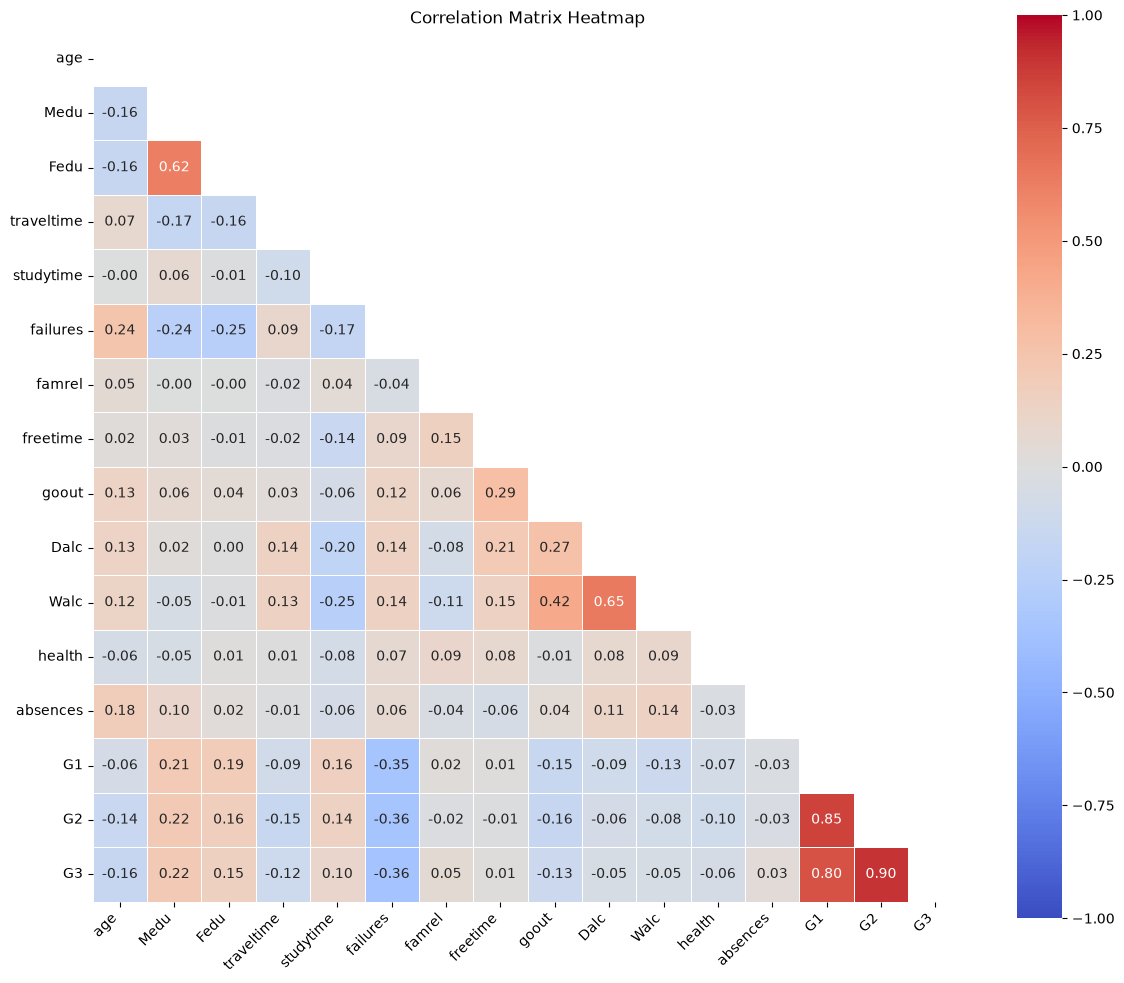

In [3]:
# Importing Data from csv file and Creating a correlation heatmap

df = pd.read_csv('student-mat.csv', sep=';')

plt.figure(figsize=(12, 10))
corr_matrix = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

features selected on the basis of correlation greater than 0.1 

In [50]:
cols = ['studytime', 'age', 'Medu', 'Fedu',
        'traveltime', 'failures', 'goout','G1', 'G2','G3' ]

df = pd.read_csv('student-mat.csv', usecols=cols, sep=';')

print(df.head())
print(df.shape)

   age  Medu  Fedu  traveltime  studytime  failures  goout  G1  G2  G3
0   18     4     4           2          2         0      4   5   6   6
1   17     1     1           1          2         0      3   5   5   6
2   15     1     1           1          2         3      2   7   8  10
3   15     4     2           1          3         0      2  15  14  15
4   16     3     3           1          2         0      2   6  10  10
(395, 10)


In [51]:
df['Pass_Fail'] = np.where(df['G3'] >= 10, 1, 0)

print(df[['G3', 'Pass_Fail']].head(10))

print(df['Pass_Fail'].value_counts())

   G3  Pass_Fail
0   6          0
1   6          0
2  10          1
3  15          1
4  10          1
5  15          1
6  11          1
7   6          0
8  19          1
9  15          1
Pass_Fail
1    265
0    130
Name: count, dtype: int64


In [52]:
features = ['studytime', 'age', 'Medu', 'Fedu',
            'traveltime', 'failures', 'goout','G1', 'G2']

X = df[features].to_numpy()

y = df['Pass_Fail'].to_numpy()

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (395, 9)
Shape of y: (395,)


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=62,
    stratify=y
)

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Training samples: 316
Testing samples: 79


In [54]:
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

classifier.fit(X_train, y_train)
predictions = classifier.predict(X_test)

print("Model training completed!")

Model training completed!


In [55]:
accuracy = accuracy_score(y_test, predictions)

precision = precision_score(y_test, predictions)

recall = recall_score(y_test, predictions)

f1 = f1_score(y_test, predictions)

print(f"Accuracy = {accuracy:.4f}")
print(f"Precision = {precision:.4f}")
print(f"Recall = {recall:.4f}")
print(f"F1 Score = {f1:.4f}")

Accuracy = 0.8987
Precision = 0.9412
Recall = 0.9057
F1 Score = 0.9231


Confusion Matrix:
[[23  3]
 [ 5 48]]


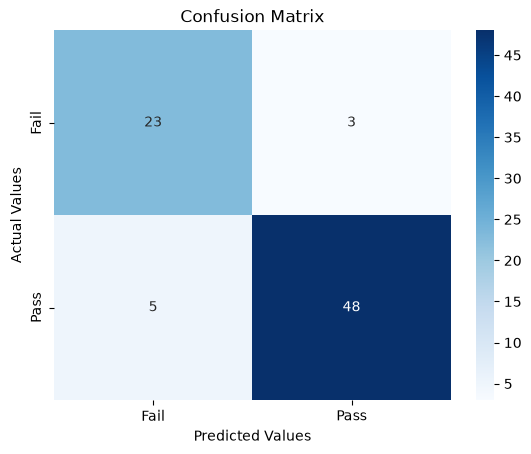

In [56]:
cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix')
plt.show()

In [57]:
print(classification_report(
    y_test,
    predictions,
    target_names=['Fail', 'Pass']
))

              precision    recall  f1-score   support

        Fail       0.82      0.88      0.85        26
        Pass       0.94      0.91      0.92        53

    accuracy                           0.90        79
   macro avg       0.88      0.90      0.89        79
weighted avg       0.90      0.90      0.90        79



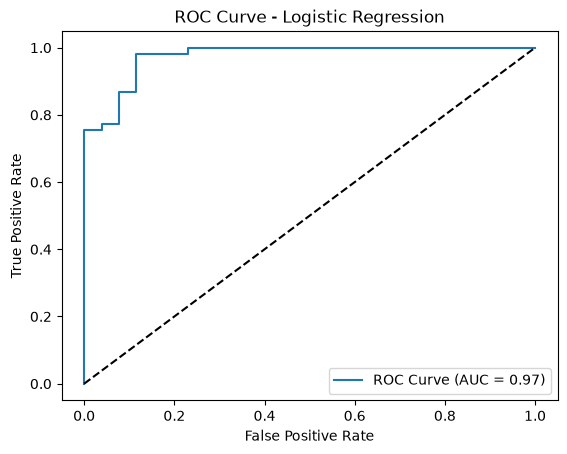

ROC AUC Score: 0.9746008708272859


In [58]:
from sklearn.metrics import roc_curve, auc

y_prob = classifier.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.show()

print("ROC AUC Score:", roc_auc)

In [64]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_all))

print("Precision:", precision_score(y_test, y_pred_all))

print("Recall:", recall_score(y_test, y_pred_all))

print("F1 Score:", f1_score(y_test, y_pred_all))

Accuracy: 0.6962025316455697
Precision: 0.704225352112676
Recall: 0.9433962264150944
F1 Score: 0.8064516129032258
